# Challenge · qr-bill-reader

*Book 27 · Deep Learning on Images & Signals · Shelf VII -- the book's closing challenge*

**The question.** A photo of a Swiss QR bill arrives. How many of its five payment fields --
IBAN, amount, reference, creditor name and creditor city -- can be read correctly, and how does
that fall as the photo gets worse? And when the QR code and the printed text disagree, is the
mismatch caught?

**The number.** The share of fields read correctly, per photo quality, for four readers:
the QR code alone; OCR with patterns and check digits; OCR read by Claude; and the combined
reader that takes the QR code when it decodes and Claude's reading when it does not.

**The data.** 30 invented bills (no real IBAN, person or company), each photographed at five
qualities -- 150 images. Six bills are *tampered*: the printed amount or IBAN differs from what
the QR code says, the shape of a classic invoice fraud.

**Replay.** OCR and the Claude calls are recorded beside this notebook (`recordings/`), keyed
by a hash of each request, so the notebook runs offline and gives the same numbers on any
machine. `BOOKSHELF_LIVE=ocr` re-runs the OCR, `BOOKSHELF_LIVE=all` also asks Claude for
anything not yet recorded.

In [1]:
import importlib.metadata as md
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ds_toolbox import llm, tracking, viz
from ds_toolbox import qrbills as qb

viz.use_style()
LIVE = os.environ.get("BOOKSHELF_LIVE", "")
HERE = Path.cwd()
GENERATOR = "qrbills-v1"          # bump when the bills or the distortions change
N_BILLS, N_TAMPERED = 30, 6

bills = qb.generate_bills(N_BILLS, seed=27)
rng = np.random.default_rng(270)
tampered_ids = set(rng.choice(N_BILLS, N_TAMPERED, replace=False).tolist())
printed, tamper_field = {}, {}
for k, b in enumerate(bills):
    if k in tampered_ids:
        printed[b.bill_id], tamper_field[b.bill_id] = qb.tamper(b, rng)
    else:
        printed[b.bill_id] = b

images = {}
for k, b in enumerate(bills):
    clean = qb.render(b, printed=printed[b.bill_id])
    for level in qb.QUALITY_LEVELS:
        images[(b.bill_id, level)] = qb.distort(clean, level, seed=1000 * k + level)
print(len(images), "images ·", len(tamper_field), "tampered bills:", dict(sorted(tamper_field.items())))

150 images · 6 tampered bills: {'bill-010': 'amount', 'bill-014': 'iban', 'bill-020': 'amount', 'bill-023': 'iban', 'bill-024': 'iban', 'bill-029': 'amount'}


Five photo qualities of one bill:

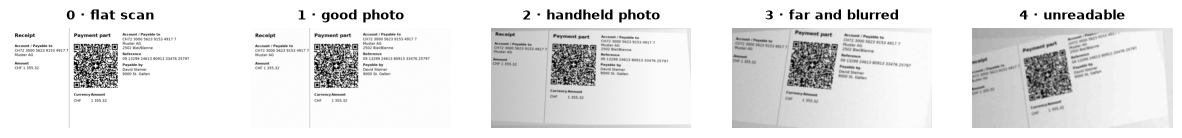

In [2]:
fig, axes = plt.subplots(1, 5, figsize=(15, 2.2))
for ax, level in zip(axes, qb.QUALITY_LEVELS, strict=True):
    ax.imshow(images[(bills[0].bill_id, level)])
    ax.set_title(f"{level} · {qb.QUALITY_LEVELS[level]}", fontsize=9)
    ax.axis("off")

## 1 · The QR code

OpenCV's detector, tried on the photo and then on a sharpened, binarised copy (chapter 4). A
decoded payload is parsed into the five fields. What the QR says is the *truth of the code*; the
ground truth for scoring is the bill as generated.

In [3]:
# decoding is recorded like the OCR below: its result feeds the Claude requests, so a decoder that
# behaves a hair differently on another machine must not change what is replayed
qr_store = llm.Recorder(HERE / "recordings" / "qr.json", live=LIVE in ("ocr", "all"),
                        call=lambda _c, req: (qb.decode_qr(images[(req["bill"], req["level"])]), {}))
qr = {}
for key in images:
    payload = qr_store.ask({"task": "qr", "generator": GENERATOR, "bill": key[0], "level": key[1]})
    qr[key] = qb.parse_payload(payload) if payload else None
qr_store.save()
decoded = pd.Series({k: v is not None for k, v in qr.items()})
decoded.groupby(level=1).mean().rename("QR decoded").to_frame().T

,0,1,2,3,4
QR decoded,1.0,1.0,1.0,0.0,0.0


## 2 · OCR of the printed fields

RapidOCR (a PP-OCRv4 detector and recogniser, run through ONNX on the CPU), recorded per image.
Each line keeps the centre of its box as a fraction of the image: the receipt strip on the left
repeats the IBAN and the name, and position is how a reader tells the two apart.

In [4]:
ENGINE = f"rapidocr-onnxruntime {md.version('rapidocr-onnxruntime')}"
ocr_store = llm.Recorder(HERE / "recordings" / "ocr.json", call=lambda _c, req: (qb.ocr_lines(images[
    (req["bill"], req["level"])]), {}), live=LIVE in ("ocr", "all"))


def ocr_request(key):
    return {"task": "ocr", "generator": GENERATOR, "engine": ENGINE, "format": "text-x-y",
            "bill": key[0], "level": key[1]}


lines = {key: ocr_store.ask(ocr_request(key)) for key in images}
ocr_store.save()
print("example, level 3:", qb.line_texts(lines[(bills[0].bill_id, 3)])[:12])

example, level 3: ['Paymentpart', 'Account/Payable te', 'Acteunt/Peyableto', 'CH7230005623915349177', 'CH7230005623915349177', 'MusterAG', 'MusterAG', '23028e/ene', 'Reference', 'OHF1355.32', '091329924613809133347625797', 'Payable bry']


## 3 · Reading the fields: patterns and check digits

`extract_by_rules` finds the IBAN and the 27-digit reference by pattern, repairs a single OCR
confusion when -- and only when -- exactly one candidate passes the check digit, takes the most
frequent amount, and reads the creditor from the lines after the IBAN.

In [5]:
rules = {key: qb.extract_by_rules(ln) for key, ln in lines.items()}

## 4 · Reading the fields: Claude

One structured call per image that has any text: the OCR lines, and the decoded QR fields when
there are some. Claude returns the five fields *as printed* and a verdict on whether print and
code agree. It may repair a digit only by a check digit, like the rules -- it is told not to
guess.

In [6]:
SYSTEM = (
    "You read the payment part of a Swiss QR bill from OCR output. Each OCR line is [text, x, y], "
    "the centre of the line as a fraction of the photo's width and height; lines with x below about "
    "0.3 belong to the receipt strip, which repeats some fields. OCR drops spaces, confuses "
    "similar characters and loses accents. Return each field exactly as PRINTED on the bill: the "
    "IBAN and the 27-digit QR reference without spaces, the amount as digits with a decimal point, "
    "the creditor's name, and the creditor's city (without its postcode). You may correct an OCR "
    "error only where the evidence supports it: restore spaces and accents in names and Swiss "
    "place names, and change a single misread digit only if the IBAN (mod 97) or the reference "
    "(mod 10, recursive) then passes its check. Never invent a value: return an empty string for a "
    "field you cannot read. If QR fields are given, compare them with what is printed and say "
    "whether they agree; ignore differences that are only OCR noise."
)
FIELD_PROPS = {f: {"type": "string"} for f in qb.FIELDS}
SCHEMA = {
    "type": "object",
    "properties": {**FIELD_PROPS,
                   "verdict": {"type": "string", "enum": ["consistent", "mismatch", "no_qr"]},
                   "mismatched_fields": {"type": "array", "items": {"type": "string", "enum": list(qb.FIELDS)}}},
    "required": [*qb.FIELDS, "verdict", "mismatched_fields"],
    "additionalProperties": False,
}


def claude_request(key):
    body = {"ocr_lines": lines[key], "qr_fields": qr[key]}
    return {"task": "qr-bill", "model": llm.MODEL, "effort": "low", "system": SYSTEM, "schema": SCHEMA,
            "user": json.dumps(body, ensure_ascii=False, indent=1)}


needs_claude = [key for key in images if len(lines[key]) >= 3]
claude_store = llm.Recorder(HERE / "recordings" / "claude.json", call=llm.call_claude,
                            client=llm.claude_client() if LIVE == "all" else None, live=LIVE == "all")
pending = claude_store.missing([claude_request(k) for k in needs_claude])
print(f"{len(needs_claude)} images go to Claude ({len(images) - len(needs_claude)} have no text) · "
      f"{len(pending)} not yet recorded")
claude = {key: claude_store.ask(claude_request(key)) for key in needs_claude}
claude_store.save()
usage = claude_store.usage()
print(f"recorded: {usage['calls']} calls, {usage['input_tokens']:,} input and {usage['output_tokens']:,} "
      f"output tokens -- about ${usage['input_tokens'] * 4e-6 + usage['output_tokens'] * 20e-6:.2f} "
      "at the Opus 5.5 list price")

135 images go to Claude (15 have no text) · 0 not yet recorded
recorded: 135 calls, 181,384 input and 47,605 output tokens -- about $1.68 at the Opus 5.5 list price


## 5 · Four readers, scored

In [7]:
truth = {b.bill_id: b.fields() for b in bills}
printed_truth = {bid: p.fields() for bid, p in printed.items()}
empty = dict.fromkeys(qb.FIELDS)


def reading(name, key):
    if name == "QR code alone":
        return qr[key] or empty
    if name == "OCR + rules":
        return rules[key]
    if name == "OCR + Claude":
        return claude.get(key, empty)
    combined = qr[key] or claude.get(key, empty)
    if name.startswith("combined: QR, else Claude"):
        return combined
    # check digits enforced: an IBAN or reference that fails its check is dropped, not trusted
    checks = {"iban": qb.iban_valid, "reference": qb.reference_valid}
    return {f: (v if f not in checks or not v or checks[f](v) else "") for f, v in combined.items()}


READERS = ["QR code alone", "OCR + rules", "OCR + Claude", "combined: QR, else Claude",
           "combined, check digits enforced"]
rows = []
for key in images:
    bid, level = key
    # a printed reading is scored against what is printed; the QR code against the bill itself
    for name in READERS:
        got = reading(name, key)
        target = truth[bid] if (name == "QR code alone" or (name.startswith("combined") and qr[key])) \
            else printed_truth[bid]
        for field in qb.FIELDS:
            g, want = qb.normalise(field, got.get(field)), qb.normalise(field, target[field])
            rows.append({"reader": name, "level": level, "field": field, "correct": g == want,
                         "wrong": g is not None and g != want, "tampered": bid in tamper_field})
scores = pd.DataFrame(rows)
by_level = scores.groupby(["reader", "level"])["correct"].mean().unstack("level").reindex(READERS)
by_level.columns = [f"{c} · {qb.QUALITY_LEVELS[c]}" for c in by_level.columns]
(by_level * 100).round(0)

,0 · flat scan,1 · good photo,2 · handheld photo,3 · far and blurred,4 · unreadable
reader,,,,,
QR code alone,100.0,100.0,100.0,0.0,0.0
OCR + rules,93.0,93.0,87.0,60.0,0.0
OCR + Claude,100.0,100.0,100.0,83.0,0.0
"combined: QR, else Claude",100.0,100.0,100.0,83.0,0.0
"combined, check digits enforced",100.0,100.0,100.0,83.0,0.0


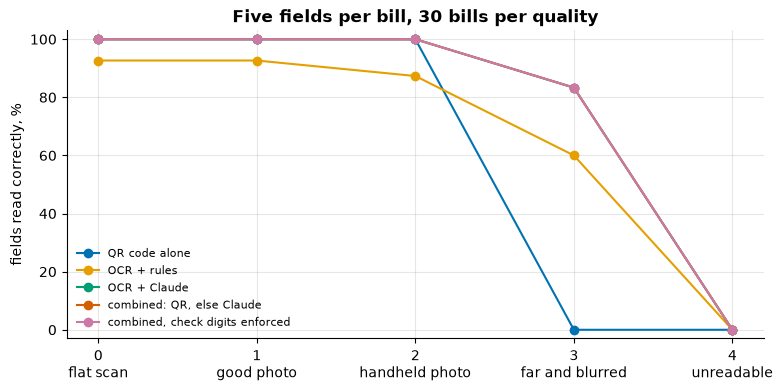

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
for name in READERS:
    ax.plot(list(qb.QUALITY_LEVELS), by_level.loc[name].to_numpy() * 100, marker="o", label=name)
ax.set(xticks=list(qb.QUALITY_LEVELS), xticklabels=[f"{k}\n{v}" for k, v in qb.QUALITY_LEVELS.items()],
       ylabel="fields read correctly, %", ylim=(-3, 103), title="Five fields per bill, 30 bills per quality")
ax.legend(fontsize=8)

**Per field**, over the readable qualities 0-3:

In [9]:
per_field = (scores[scores.level <= 3].groupby(["reader", "field"])["correct"].mean()
             .unstack("field").reindex(READERS)[list(qb.FIELDS)])
(per_field * 100).round(0)

field,iban,amount,reference,creditor_name,creditor_city
reader,,,,,
QR code alone,75.0,75.0,75.0,75.0,75.0
OCR + rules,92.0,98.0,96.0,62.0,68.0
OCR + Claude,94.0,95.0,97.0,96.0,98.0
"combined: QR, else Claude",94.0,95.0,97.0,96.0,98.0
"combined, check digits enforced",94.0,95.0,97.0,96.0,98.0


## Wrong is worse than empty

For a payment, a field left empty is a question to the user; a field filled in wrongly is money
sent to the wrong account. So the second number: the share of fields a reader returned **filled
in but wrong**.

In [10]:
wrong = scores.groupby(["reader", "level"])["wrong"].mean().unstack("level").reindex(READERS)
wrong.columns = [f"{c} · {qb.QUALITY_LEVELS[c]}" for c in wrong.columns]
(wrong * 100).round(1)

,0 · flat scan,1 · good photo,2 · handheld photo,3 · far and blurred,4 · unreadable
reader,,,,,
QR code alone,0.0,0.0,0.0,0.0,0.0
OCR + rules,7.3,7.3,12.7,24.0,6.0
OCR + Claude,0.0,0.0,0.0,6.0,5.3
"combined: QR, else Claude",0.0,0.0,0.0,6.0,5.3
"combined, check digits enforced",0.0,0.0,0.0,4.0,5.3


In [11]:
claude_wrong = scores[(scores.reader == "OCR + Claude") & scores.wrong]
claude_wrong.groupby(["level", "field"]).size().rename("wrong fields").to_frame()

wrong fields
level field                      
3     amount                    1
      creditor_name             5
      reference                 3
4     amount                    8

## 6 · Catching a tampered bill

Where the QR code decodes, print and code can be compared. The rules compare the normalised
fields directly; Claude gives its verdict. A tampered bill should be flagged, an honest one not.

In [12]:
verdicts = []
for key in images:
    if qr[key] is None or key not in claude:
        continue
    bid = key[0]
    rule_flag = any(qb.normalise(f, rules[key].get(f)) != qb.normalise(f, qr[key][f]) for f in ("iban", "amount"))
    verdicts.append({"level": key[1], "tampered": bid in tamper_field, "rules": rule_flag,
                     "Claude": claude[key]["verdict"] == "mismatch"})
v = pd.DataFrame(verdicts)


def detection(col):
    tp = int((v[col] & v.tampered).sum())
    fp = int((v[col] & ~v.tampered).sum())
    fn = int((~v[col] & v.tampered).sum())
    return {"images compared": len(v), "tampered caught": f"{tp} of {tp + fn}",
            "honest bills flagged": f"{fp} of {int((~v.tampered).sum())}",
            "precision": tp / (tp + fp) if tp + fp else float("nan"),
            "recall": tp / (tp + fn) if tp + fn else float("nan")}


pd.DataFrame({c: detection(c) for c in ["rules", "Claude"]}).T

,images compared,tampered caught,honest bills flagged,precision,recall
rules,90,18 of 18,0 of 72,1.0,1.0
Claude,90,18 of 18,0 of 72,1.0,1.0


## Recorded

In [13]:
combined = by_level.loc["combined: QR, else Claude"]
summary = {
    "challenge": "qr-bill-reader",
    "data": f"{N_BILLS} invented Swiss QR bills x {len(qb.QUALITY_LEVELS)} qualities, {N_TAMPERED} tampered",
    "metric": "share of the five fields read correctly",
    "by_reader_and_quality": {r: {str(lvl): round(float(x), 3)
                                  for lvl, x in zip(qb.QUALITY_LEVELS, by_level.loc[r], strict=True)}
                              for r in READERS},
    "wrong_not_empty": {r: {str(lvl): round(float(x), 3)
                            for lvl, x in zip(qb.QUALITY_LEVELS, wrong.loc[r], strict=True)}
                        for r in READERS},
    "tamper_detection": {c: {k: (round(x, 3) if isinstance(x, float) else x) for k, x in detection(c).items()}
                         for c in ["rules", "Claude"]},
    "claude_usage": usage,
    "engine": ENGINE,
    "model": llm.MODEL,
}
(HERE / "results.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
tracking.log_run("qr-bill-reader", {"bills": N_BILLS, "engine": ENGINE},
                 {f"combined_q{k}": float(x) for k, x in zip(qb.QUALITY_LEVELS, combined, strict=True)},
                 root=HERE, use_mlflow=False)
print(json.dumps(summary["by_reader_and_quality"], indent=1))

{
 "QR code alone": {
  "0": 1.0,
  "1": 1.0,
  "2": 1.0,
  "3": 0.0,
  "4": 0.0
 },
 "OCR + rules": {
  "0": 0.927,
  "1": 0.927,
  "2": 0.873,
  "3": 0.6,
  "4": 0.0
 },
 "OCR + Claude": {
  "0": 1.0,
  "1": 1.0,
  "2": 1.0,
  "3": 0.833,
  "4": 0.0
 },
 "combined: QR, else Claude": {
  "0": 1.0,
  "1": 1.0,
  "2": 1.0,
  "3": 0.833,
  "4": 0.0
 },
 "combined, check digits enforced": {
  "0": 1.0,
  "1": 1.0,
  "2": 1.0,
  "3": 0.833,
  "4": 0.0
 }
}

## What the number says

- **On a readable photo (qualities 0-2) the QR code is enough.** It decodes every image and reads
  every field; so does Claude reading the OCR text. Patterns and check digits alone miss 7-13 % of
  the fields -- almost all of them names and places that OCR read *nearly* right ("Zurich",
  "MusterAG").
- **On a far, blurred photo (quality 3) the QR code is gone, and the text is the only way in.**
  The rules recover 60 % of the fields, Claude 83 %. Claude's gain is in the creditor's name and
  city, where it restores spaces and accents; on the digits the rules and Claude are close.
- **On an unreadable photo (quality 4) every reader reads nothing correctly -- but not every
  reader says so.** Claude filled in an amount on several unreadable photos although told never to
  guess, and the rules matched a stray number as well. A check digit catches a guessed IBAN or
  reference; nothing catches a guessed amount. The fix is upstream: chapter 5 tells a quality-4
  photo apart without error, and a reader should answer "unreadable" there instead of asking a model.
- **Enforcing the check digits is free and only helps.** It drops the three references Claude
  misread at quality 3 -- wrong fields fall from 6 % to 4 % -- and costs no correct field.
- **Tampering is caught wherever the QR code decodes**, by the rules and by Claude alike: every
  tampered bill flagged, no honest bill flagged. Where the code does not decode, nothing can be
  compared -- the honest answer is that the bill cannot be verified.
- **Cost:** 135 Claude calls at effort `low`, recorded once for about $1.70; every later run replays
  them for nothing.

**Back to the book:** [Book 27 · Deep Learning on Images & Signals](../README.md)